## 0. 掛載 Drive & 載入設定

In [ ]:
!pip install -q albumentations

import os, math, random, glob, zipfile
import numpy as np
import pandas as pd
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.utils import register_keras_serializable
import matplotlib.pyplot as plt
from google.colab import drive , files
from tensorflow.keras import layers as L

drive.mount('/content/drive')

# ── 路徑與設定（與 train.ipynb 保持一致）────────────────────────
DATA_DIR   = "/content/data"
TRAIN_CSV  = os.path.join(DATA_DIR, "train.csv")
TRAIN_DIR  = os.path.join(DATA_DIR, "train_images")
MODEL_DIR  = "/content/drive/MyDrive/實驗結果"

IMG_H, IMG_W   = 128, 800
INPUT_H, INPUT_W = IMG_H, IMG_W
N_CLASSES      = 4
BATCH          = 8
BACKBONE       = "efficientnetb4"  # 'resnet34' | 'inceptionv3' | 'efficientnetb4'
ARCH           = "unet"
NOISE_SETTING  = "none"
# TARGET_LAYER   = "activation_9"
RANDOM_SEED    = 42
LR     = 1e-5
UPSAMPLE_RATIO = {1:6, 2:12, 3:3, 4:6}
print("設定完成")


Mounted at /content/drive
設定完成


## 1. 共用函式（RLE / 資料載入）

In [ ]:
def read_train_csv(path):
    if not os.path.exists(path):
        return pd.DataFrame(columns=["ImageId_ClassId","EncodedPixels"])
    raw  = pd.read_csv(path)
    cols = set(map(str, raw.columns))
    if {"ImageId_ClassId","EncodedPixels"}.issubset(cols):
        return raw[["ImageId_ClassId","EncodedPixels"]].copy()
    df = raw[["ImageId","ClassId","EncodedPixels"]].copy()
    df["ImageId_ClassId"] = df["ImageId"].astype(str)+"_"+df["ClassId"].astype(str)
    return df[["ImageId_ClassId","EncodedPixels"]]

def rle_decode(mask_rle, shape):
    if not isinstance(mask_rle, str) or not mask_rle.strip():
        return np.zeros(shape, dtype=np.uint8)
    s = mask_rle.strip().split()
    starts = np.asarray(s[0::2], dtype=int)-1
    img    = np.zeros(shape[0]*shape[1], dtype=np.uint8)
    for lo, ln in zip(starts, np.asarray(s[1::2],dtype=int)):
        img[lo:lo+ln] = 1
    return img.reshape(shape, order="F")
print("✅ 工具函式載入完成")


✅ 工具函式載入完成


In [ ]:
import albumentations as A
import random

# 上傳 kaggle.json 金鑰後自動下載資料集
files.upload()
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle competitions download -c severstal-steel-defect-detection -p {DATA_DIR}

for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
    with zipfile.ZipFile(z) as zz:
        zz.extractall(DATA_DIR)
print("✅ 解壓完成:", os.listdir(DATA_DIR))

Saving kaggle.json to kaggle.json
100% 1.57G/1.57G [00:53<00:00, 31.6MB/s]

✅ 解壓完成: ['train_images', 'severstal-steel-defect-detection.zip', 'train.csv', 'test_images', 'sample_submission.csv']


In [ ]:
df = read_train_csv(TRAIN_CSV)
df["ImageId"] = df["ImageId_ClassId"].astype(str).str.rsplit("_", n=1).str[0]
groups = df.groupby("ImageId")
all_ids = sorted(os.path.basename(p) for p in glob.glob(f"{TRAIN_DIR}/*.jpg"))

# 與訓練 notebook 使用相同 RANDOM_SEED、相同切分邏輯，
# 確保這裡重建出來的 va_ids / te_ids 與訓練時預留的完全一致
rng = np.random.RandomState(RANDOM_SEED)
idx = rng.permutation(len(all_ids))
n = len(all_ids)
a, b = int(0.6 * n), int(0.8 * n)

va_ids = [all_ids[i] for i in idx[a:b]]
te_ids = [all_ids[i] for i in idx[b:]]

print(f"✅ 切分重建完成 — val={len(va_ids)}  test={len(te_ids)}")

✅ 切分重建完成 — val=2514  test=2514


In [ ]:
def load_image_and_mask(img_id, df_group):
    img0 = cv2.imread(os.path.join(TRAIN_DIR, img_id), cv2.IMREAD_GRAYSCALE)
    if img0 is None:
        img0 = np.zeros((256, 1600), np.uint8)
    H0, W0 = img0.shape
    mask4 = np.zeros((H0, W0, N_CLASSES), np.uint8)
    if df_group is not None:
        for _, row in df_group.iterrows():
            ch = int(str(row["ImageId_ClassId"]).rsplit("_", 1)[1]) - 1
            rle = row.get("EncodedPixels", "")
            if isinstance(rle, str) and rle.strip():
                mask4[..., ch] = rle_decode(rle, (H0, W0))
    img = cv2.resize(img0, (IMG_W, IMG_H), interpolation=cv2.INTER_AREA)
    mask = np.stack(
        [cv2.resize(mask4[..., k], (IMG_W, IMG_H), interpolation=cv2.INTER_NEAREST) for k in range(N_CLASSES)],
        axis=-1,
    )
    return img, mask


def preprocess_image(img_u8):
    """依 backbone 套用對應的正規化方式（須與訓練時完全一致）。"""
    if img_u8.ndim == 2:
        img_u8 = img_u8[..., None]
    if img_u8.shape[-1] == 1:
        img_u8 = np.repeat(img_u8, 3, axis=-1)
    img = img_u8.astype("float32")
    if BACKBONE == "resnet50":
        return tf.keras.applications.resnet50.preprocess_input(img)
    elif BACKBONE == "inceptionv3":
        return tf.keras.applications.inception_v3.preprocess_input(img)
    else:
        return tf.keras.applications.efficientnet.preprocess_input(img)


def make_gauss_noise(std):
    def _fn(image, **kw):
        noisy = image.astype(np.float32) + np.random.normal(0, std, image.shape)
        return np.clip(noisy, 0, 255).astype(np.uint8)
    return A.Lambda(image=_fn, p=1.0)


def make_salt_pepper(p_thr, s_thr):
    def _fn(image, **kw):
        img = image.copy()
        r = np.random.rand(*image.shape[:2])
        img[r < p_thr] = 0
        img[r > s_thr] = 255
        return img
    return A.Lambda(image=_fn, p=1.0)


def build_test_aug(noise_setting="none"):
    if noise_setting in ["none", None]:
        return A.Compose([])
    if noise_setting == "low":
        return A.Compose([make_gauss_noise(20), make_salt_pepper(0.05, 0.95)])
    if noise_setting == "high":
        return A.Compose(
            [A.GaussianBlur(blur_limit=(5, 5), p=1.0), make_gauss_noise(50), make_salt_pepper(0.10, 0.90)]
        )
    raise ValueError(f"Unknown noise_setting: {noise_setting}")

In [ ]:
def gen(ids, aug):
    """單次走訪（不打亂、不重複），確保評估結果可重現。"""
    for img_id in ids:
        g = groups.get_group(img_id) if img_id in groups.groups else None
        img_u8, mask_u8 = load_image_and_mask(img_id, g)
        if aug:
            x = img_u8 if img_u8.ndim == 3 else img_u8[..., None]
            out = aug(image=x, mask=mask_u8)
            img_u8, mask_u8 = out["image"], out["mask"]
        yield preprocess_image(img_u8), mask_u8.astype("float32")


def make_ds(ids, aug):
    sig = (
        tf.TensorSpec((IMG_H, IMG_W, 3), tf.float32),
        tf.TensorSpec((IMG_H, IMG_W, N_CLASSES), tf.float32),
    )
    return (
        tf.data.Dataset.from_generator(lambda: gen(ids, aug), output_signature=sig)
        .batch(BATCH)
        .prefetch(tf.data.AUTOTUNE)
    )


test_aug = build_test_aug(NOISE_SETTING)
val_aug   = build_test_aug(NOISE_SETTING)

val_ds = make_ds(va_ids, val_aug)
test_ds = make_ds(te_ids, test_aug)

print(f"✅ Dataset 重建完成 — val={len(va_ids)}  test={len(te_ids)}")

✅ Dataset 重建完成 — val=2514  test=2514


In [ ]:
import tensorflow as tf
from tensorflow.keras.utils import register_keras_serializable


@register_keras_serializable(package="custom", name="macro_double_soft_dice_loss")
def macro_double_soft_dice_loss(y_true, y_pred, eps=1e-7):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    inter = tf.reduce_sum(y_true * y_pred, axis=[1, 2])      # (B, C)
    denom = tf.reduce_sum(y_true + y_pred, axis=[1, 2])      # (B, C)
    dice = (2.0 * inter + eps) / (denom + eps)                # (B, C)

    return 1.0 - tf.reduce_mean(dice)                         # macro over B and C


@register_keras_serializable(package="custom", name="per_class_focal_loss")
def per_class_focal_loss(y_true, y_pred, alpha=(0.6, 0.85, 0.35, 0.35), gamma=2.0, eps=1e-7):
    """
    alpha: (a1, a2, a3, a4) 對應 Defect1~4。
    依論文 3-2 節資料集像素佔比反比設定：Defect2（細線刮痕，佔比最低 0.825%）
    給最大 alpha，強化稀有類別的梯度權重。
    此組數值對應論文 Table 4-2 / 4-3 / 4-4 報告之最終結果。
    """
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), eps, 1.0 - eps)

    alpha = tf.constant(alpha, dtype=tf.float32)     # (C,)
    alpha = tf.reshape(alpha, (1, 1, 1, -1))          # broadcast -> (1, 1, 1, C)

    ce = -(y_true * tf.math.log(y_pred) + (1.0 - y_true) * tf.math.log(1.0 - y_pred))
    pt = y_true * y_pred + (1.0 - y_true) * (1.0 - y_pred)

    weight = alpha * y_true + (1.0 - alpha) * (1.0 - y_true)
    fl = weight * tf.pow(1.0 - pt, gamma) * ce

    return tf.reduce_mean(fl)


@register_keras_serializable(package="custom", name="combined_loss_pc")
def combined_loss(y_true, y_pred):
    return per_class_focal_loss(y_true, y_pred) + macro_double_soft_dice_loss(y_true, y_pred)


@register_keras_serializable(package="custom", name="macro_dice_score")
def macro_dice_score(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred, axis=[1, 2])
    denominator = tf.reduce_sum(y_true + y_pred, axis=[1, 2])
    dice_score = (2.0 * intersection + 1e-7) / (denominator + 1e-7)

    return tf.reduce_mean(dice_score)


@register_keras_serializable(package="custom", name="macro_iou_score")
def macro_iou_score(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred, axis=[1, 2])
    union = tf.reduce_sum(y_true + y_pred, axis=[1, 2]) - intersection
    iou_score = (intersection + 1e-7) / (union + 1e-7)

    return tf.reduce_mean(iou_score)

In [ ]:
CUSTOM_OBJECTS = {
    "combined_loss":              combined_loss,
    "per_class_focal_loss":       per_class_focal_loss,
    "macro_double_soft_dice_loss": macro_double_soft_dice_loss,
    "macro_dice_score":           macro_dice_score,
    "macro_iou_score":            macro_iou_score,
}

##載入模型

In [ ]:
# model_name = f"{ARCH}_{BACKBONE}_{NOISE_SETTING}"
model_name = f"{ARCH}_ag_shared_{BACKBONE}"
keras_path = f"{MODEL_DIR}/{model_name}.keras"

print(model_name)
if not os.path.exists(keras_path):
    found = sorted(glob.glob(f"{MODEL_DIR}/*.keras"))
    print("⚠️ 指定模型不存在，找到："); [print(" ",f) for f in found]
    keras_path = found[-1] if found else None

model = tf.keras.models.load_model(keras_path, custom_objects=CUSTOM_OBJECTS,safe_mode=False)
print(f"✅ 載入成功：{keras_path}")


unet_ag_shared_efficientnetb4
✅ 載入成功：/content/drive/MyDrive/實驗結果/unet_ag_shared_efficientnetb4.keras


## 模型參數統計（論文 Table 4）


In [ ]:
total         = model.count_params()
trainable     = sum(tf.size(w).numpy() for w in model.trainable_weights)
non_trainable = sum(tf.size(w).numpy() for w in model.non_trainable_weights)
print(f"Total Parameters:         {total:,}")
print(f"Trainable Parameters:     {trainable:,}")
print(f"Non-Trainable Parameters: {non_trainable:,}")
print("model",model_name)

Total Parameters:         30,611,103
Trainable Parameters:     30,477,168
Non-Trainable Parameters: 133,935
model unet_ag_shared_efficientnetb4


## 定量分析

In [ ]:

# ── 建立評估用 dataset（4 channel）──
N_CLASSES = 4
val_ds_eval  = make_ds(va_ids, val_aug)
test_ds_eval = make_ds(te_ids, test_aug)


# ============================================================
# 收集預測結果
# ============================================================

def collect_preds_combined(model, ds):
    """將 4 個獨立解碼器輸出（各 (B,H,W,1)）組合成單一 (B,H,W,4) 張量。"""
    y_trues, y_probs = [], []
    for xb, yb in ds:
        y_trues.append(yb.numpy())
        preds = model.predict(xb, verbose=0)
        preds = np.concatenate(preds, axis=-1)
        y_probs.append(preds)
    return np.concatenate(y_trues, 0), np.concatenate(y_probs, 0)


# ============================================================
# DSC / IoU 計算（逐圖逐類別計算後取平均）
# 慣例：若該類別在該圖中 ground truth 與預測皆為空，視為 DSC=IoU=1.0
# ============================================================

def paper_style_dsc_iou(y_true, y_prob, thr=0.5, eps=1e-7):
    N, H, W, C = y_true.shape
    dsc_list, iou_list = [], []
    for i in range(N):
        for c in range(C):
            t = (y_true[i, :, :, c] > 0.5).astype(np.uint8)
            p = (y_prob[i, :, :, c] >= thr).astype(np.uint8)
            ts, ps = int(t.sum()), int(p.sum())
            if ts == 0 and ps == 0:
                dsc_list.append(1.0)
                iou_list.append(1.0)
            else:
                inter = int((t & p).sum())
                dsc_list.append((2 * inter + eps) / (ts + ps + eps))
                iou_list.append((inter + eps) / (ts + ps - inter + eps))
    return float(np.mean(dsc_list)), float(np.mean(iou_list))


def paper_style_dsc_iou_perclass(y_true, y_prob, thrs, eps=1e-7):
    N, H, W, C = y_true.shape
    results = []
    for c in range(C):
        thr = thrs[c]
        dsc_list, iou_list = [], []
        for i in range(N):
            t = (y_true[i, :, :, c] > 0.5).astype(np.uint8)
            p = (y_prob[i, :, :, c] >= thr).astype(np.uint8)
            ts, ps = int(t.sum()), int(p.sum())
            if ts == 0 and ps == 0:
                dsc_list.append(1.0)
                iou_list.append(1.0)
            else:
                inter = int((t & p).sum())
                dsc_list.append((2 * inter + eps) / (ts + ps + eps))
                iou_list.append((inter + eps) / (ts + ps - inter + eps))
        results.append((float(np.mean(dsc_list)), float(np.mean(iou_list))))
    return results


# ============================================================
# 執行評估
# ============================================================

print("=== 收集預測 ===")
y_true_val, y_prob_val = collect_preds_combined(model, val_ds_eval)
y_true_test, y_prob_test = collect_preds_combined(model, test_ds_eval)

d_val, i_val = paper_style_dsc_iou(y_true_val, y_prob_val)
d_test, i_test = paper_style_dsc_iou(y_true_test, y_prob_test)

# ------------------------------------------------------------
# 固定 threshold = 0.5 — 對應論文 Table 4-2 報告數字
# ------------------------------------------------------------
print("\n" + "=" * 55)
print("Test Set  (threshold = 0.5) — 對應論文 Table 4-2")
print("=" * 55)
test_pc = paper_style_dsc_iou_perclass(y_true_test, y_prob_test, [0.5] * 4)
rows_test = []
for c, (dsc, iou) in enumerate(test_pc):
    rows_test.append({"Class": f"Defect {c+1}", "Threshold": 0.50,
                       "Test DSC": round(dsc, 4), "Test IoU": round(iou, 4)})
rows_test.append({"Class": "Macro Avg", "Threshold": "–",
                   "Test DSC": round(d_test, 4), "Test IoU": round(i_test, 4)})
display(pd.DataFrame(rows_test))

print("\n" + "=" * 55)
print("Validation Set  (threshold = 0.5)  ")
print("=" * 55)
val_pc = paper_style_dsc_iou_perclass(y_true_val, y_prob_val, [0.5] * 4)
rows_val = []
for c, (dsc, iou) in enumerate(val_pc):
    rows_val.append({"Class": f"Defect {c+1}", "Threshold": 0.50,
                      "Val DSC": round(dsc, 4), "Val IoU": round(iou, 4)})
rows_val.append({"Class": "Macro Avg", "Threshold": "–",
                  "Val DSC": round(d_val, 4), "Val IoU": round(i_val, 4)})
display(pd.DataFrame(rows_val))

=== 收集預測 ===

Test Set  (threshold = 0.5) — 對應論文 Table 4-2


,Class,Threshold,Test DSC,Test IoU
0,Defect 1,0.5,0.8077,0.7970
1,Defect 2,0.5,0.9172,0.9144
2,Defect 3,0.5,0.6925,0.6406
3,Defect 4,0.5,0.9215,0.9133
4,Macro Avg,–,0.8347,0.8163



Validation Set  (threshold = 0.5)  


,Class,Threshold,Val DSC,Val IoU
0,Defect 1,0.5,0.8119,0.8037
1,Defect 2,0.5,0.9155,0.9127
2,Defect 3,0.5,0.6859,0.6328
3,Defect 4,0.5,0.9209,0.9131
4,Macro Avg,–,0.8335,0.8156


## TTA

*   TTA：原圖 + 水平翻轉 + 垂直翻轉，平均三次預測
*   Per-class threshold：在 val 集搜尋 0.1～0.95，套用到 test
*   說明這兩個技巧可以在不改架構的情況下再提升分數



In [ ]:
# ────────────────────────────────────────────────────────────────
# 1. 收集預測（支援 TTA）
# ────────────────────────────────────────────────────────────────
def collect_preds(model, ds, use_tta=False):
    """
    走訪整個 dataset，收集 ground truth 與模型預測機率。
    use_tta=True 時，對每個 batch 做水平/垂直翻轉推論後取平均，
    對應論文 3-4 節 TTA 策略。
    """
    y_trues, y_probs = [], []

    def _merge(preds):
        """CSAD U-Net 四個獨立解碼器輸出（各 (B,H,W,1)）合併為 (B,H,W,4)。"""
        if isinstance(preds, list):
            return np.concatenate(preds, axis=-1)
        return preds

    for xb, yb in ds:
        y_trues.append(yb.numpy())
        xb_np = xb.numpy()

        if use_tta:
            pred_orig = _merge(model.predict(xb_np, verbose=0))
            pred_hflip = _merge(model.predict(xb_np[:, :, ::-1, :], verbose=0))
            pred_vflip = _merge(model.predict(xb_np[:, ::-1, :, :], verbose=0))

            # 逆變換對齊回原始方向
            pred_hflip = pred_hflip[:, :, ::-1, :]
            pred_vflip = pred_vflip[:, ::-1, :, :]

            y_probs.append((pred_orig + pred_hflip + pred_vflip) / 3.0)
        else:
            y_probs.append(_merge(model.predict(xb_np, verbose=0)))

    return np.concatenate(y_trues, 0), np.concatenate(y_probs, 0)


# ────────────────────────────────────────────────────────────────
# 2. 逐類別、逐樣本計算 DSC / IoU（macro-average，對應 Table 4-2 口徑）
#    慣例：若該類別在該圖中 ground truth 與預測皆為空，視為 DSC=IoU=1.0
# ────────────────────────────────────────────────────────────────
def per_class_dsc_iou(y_true, y_prob, thresholds=None, eps=1e-7):
    N, H, W, C = y_true.shape
    if thresholds is None:
        thresholds = [0.5] * C

    results = []
    for c in range(C):
        thr = thresholds[c]
        dsc_list, iou_list = [], []
        for i in range(N):
            t = (y_true[i, :, :, c] > 0.5).astype(np.uint8)
            p = (y_prob[i, :, :, c] >= thr).astype(np.uint8)
            ts, ps = int(t.sum()), int(p.sum())
            if ts == 0 and ps == 0:
                dsc_list.append(1.0)
                iou_list.append(1.0)
            else:
                inter = int((t & p).sum())
                dsc_list.append((2 * inter + eps) / (ts + ps + eps))
                iou_list.append((inter + eps) / (ts + ps - inter + eps))
        results.append({
            "Class": f"Defect {c+1}",
            "Threshold": f"{thr:.2f}",
            "DSC": float(np.mean(dsc_list)),
            "IoU": float(np.mean(iou_list)),
        })
    return results


def display_results(val_results, test_results):
    def to_df(results, dsc_col, iou_col):
        rows, dscs, ious = [], [], []
        for r in results:
            rows.append({
                "Class": r["Class"],
                "Threshold": r["Threshold"],
                dsc_col: f"{r['DSC']:.4f}",
                iou_col: f"{r['IoU']:.4f}",
            })
            dscs.append(r["DSC"])
            ious.append(r["IoU"])
        rows.append({
            "Class": "Macro Avg",
            "Threshold": "-",
            dsc_col: f"{np.mean(dscs):.4f}",
            iou_col: f"{np.mean(ious):.4f}",
        })
        return pd.DataFrame(rows)

    print("\n" + "=" * 55)
    print("Validation Set  (TTA")
    print("=" * 55)
    display(to_df(val_results, "Val DSC", "Val IoU"))

    print("\n" + "=" * 55)
    print("Test Set  (TTA) — 對應論文 Table 4-2「CSAD U-Net+TTA」")
    print("=" * 55)
    display(to_df(test_results, "Test DSC", "Test IoU"))


# ────────────────────────────────────────────────────────────────
# 3. 主流程
# ────────────────────────────────────────────────────────────────
print("=== 收集預測（TTA）===")
y_true_val, y_prob_val = collect_preds(model, val_ds, use_tta=True)
y_true_test, y_prob_test = collect_preds(model, test_ds, use_tta=True)

val_results = per_class_dsc_iou(y_true_val, y_prob_val)
test_results = per_class_dsc_iou(y_true_test, y_prob_test)

display_results(val_results, test_results)

=== 收集預測（TTA）===

Validation Set  (TTA


,Class,Threshold,Val DSC,Val IoU
0,Defect 1,0.50,0.8904,0.8824
1,Defect 2,0.50,0.9625,0.9598
2,Defect 3,0.50,0.7161,0.6636
3,Defect 4,0.50,0.9557,0.9480
4,Macro Avg,-,0.8812,0.8635



Test Set  (TTA) — 對應論文 Table 4-2「CSAD U-Net+TTA」


,Class,Threshold,Test DSC,Test IoU
0,Defect 1,0.50,0.9020,0.8915
1,Defect 2,0.50,0.9584,0.9557
2,Defect 3,0.50,0.7165,0.6651
3,Defect 4,0.50,0.9492,0.9412
4,Macro Avg,-,0.8815,0.8634


# ================================================================
定性分析（Qualitative Analysis）— 對應論文 4-2 節<br>
隨機抽樣各類別缺陷圖片，比較 Baseline (Aboulhosn et al. 2024) 與
CSAD U-Net (Ours) 的分割遮罩輪廓，並疊加 Ground Truth 顯示。<br>

model_org : Baseline，單一輸出頭標準 U-Net，輸出 (1, H, W, 4)<br>
model     : CSAD U-Net（Ours），4 個獨立輸出頭，輸出 list of (1, H, W, 1)
# ================================================================

In [ ]:
# ── 定量與基準模型2024比較，先載入模型 ────────────────────────────────────────
model_name_org = f"{ARCH}_{BACKBONE}_none"
keras_path_org = f"{MODEL_DIR}/{model_name_org}.keras"

if not os.path.exists(keras_path_org):
    found = sorted(glob.glob(f"{MODEL_DIR}/*.keras"))
    print("⚠️ 指定模型不存在，找到："); [print(" ",f) for f in found]
    keras_path_org = found[-1] if found else None

model_org = tf.keras.models.load_model(keras_path_org, custom_objects=CUSTOM_OBJECTS,safe_mode=False)
print(f"✅ 載入成功：{keras_path_org}")

✅ 載入成功：/content/drive/MyDrive/實驗結果/unet_efficientnetb4_none.keras


隨機抽取樣本：
  Defect 1: b7fd1f63b.jpg
  Defect 2: db4867ee8.jpg
  Defect 3: c9358e43f.jpg
  Defect 4: 24fdedc37.jpg


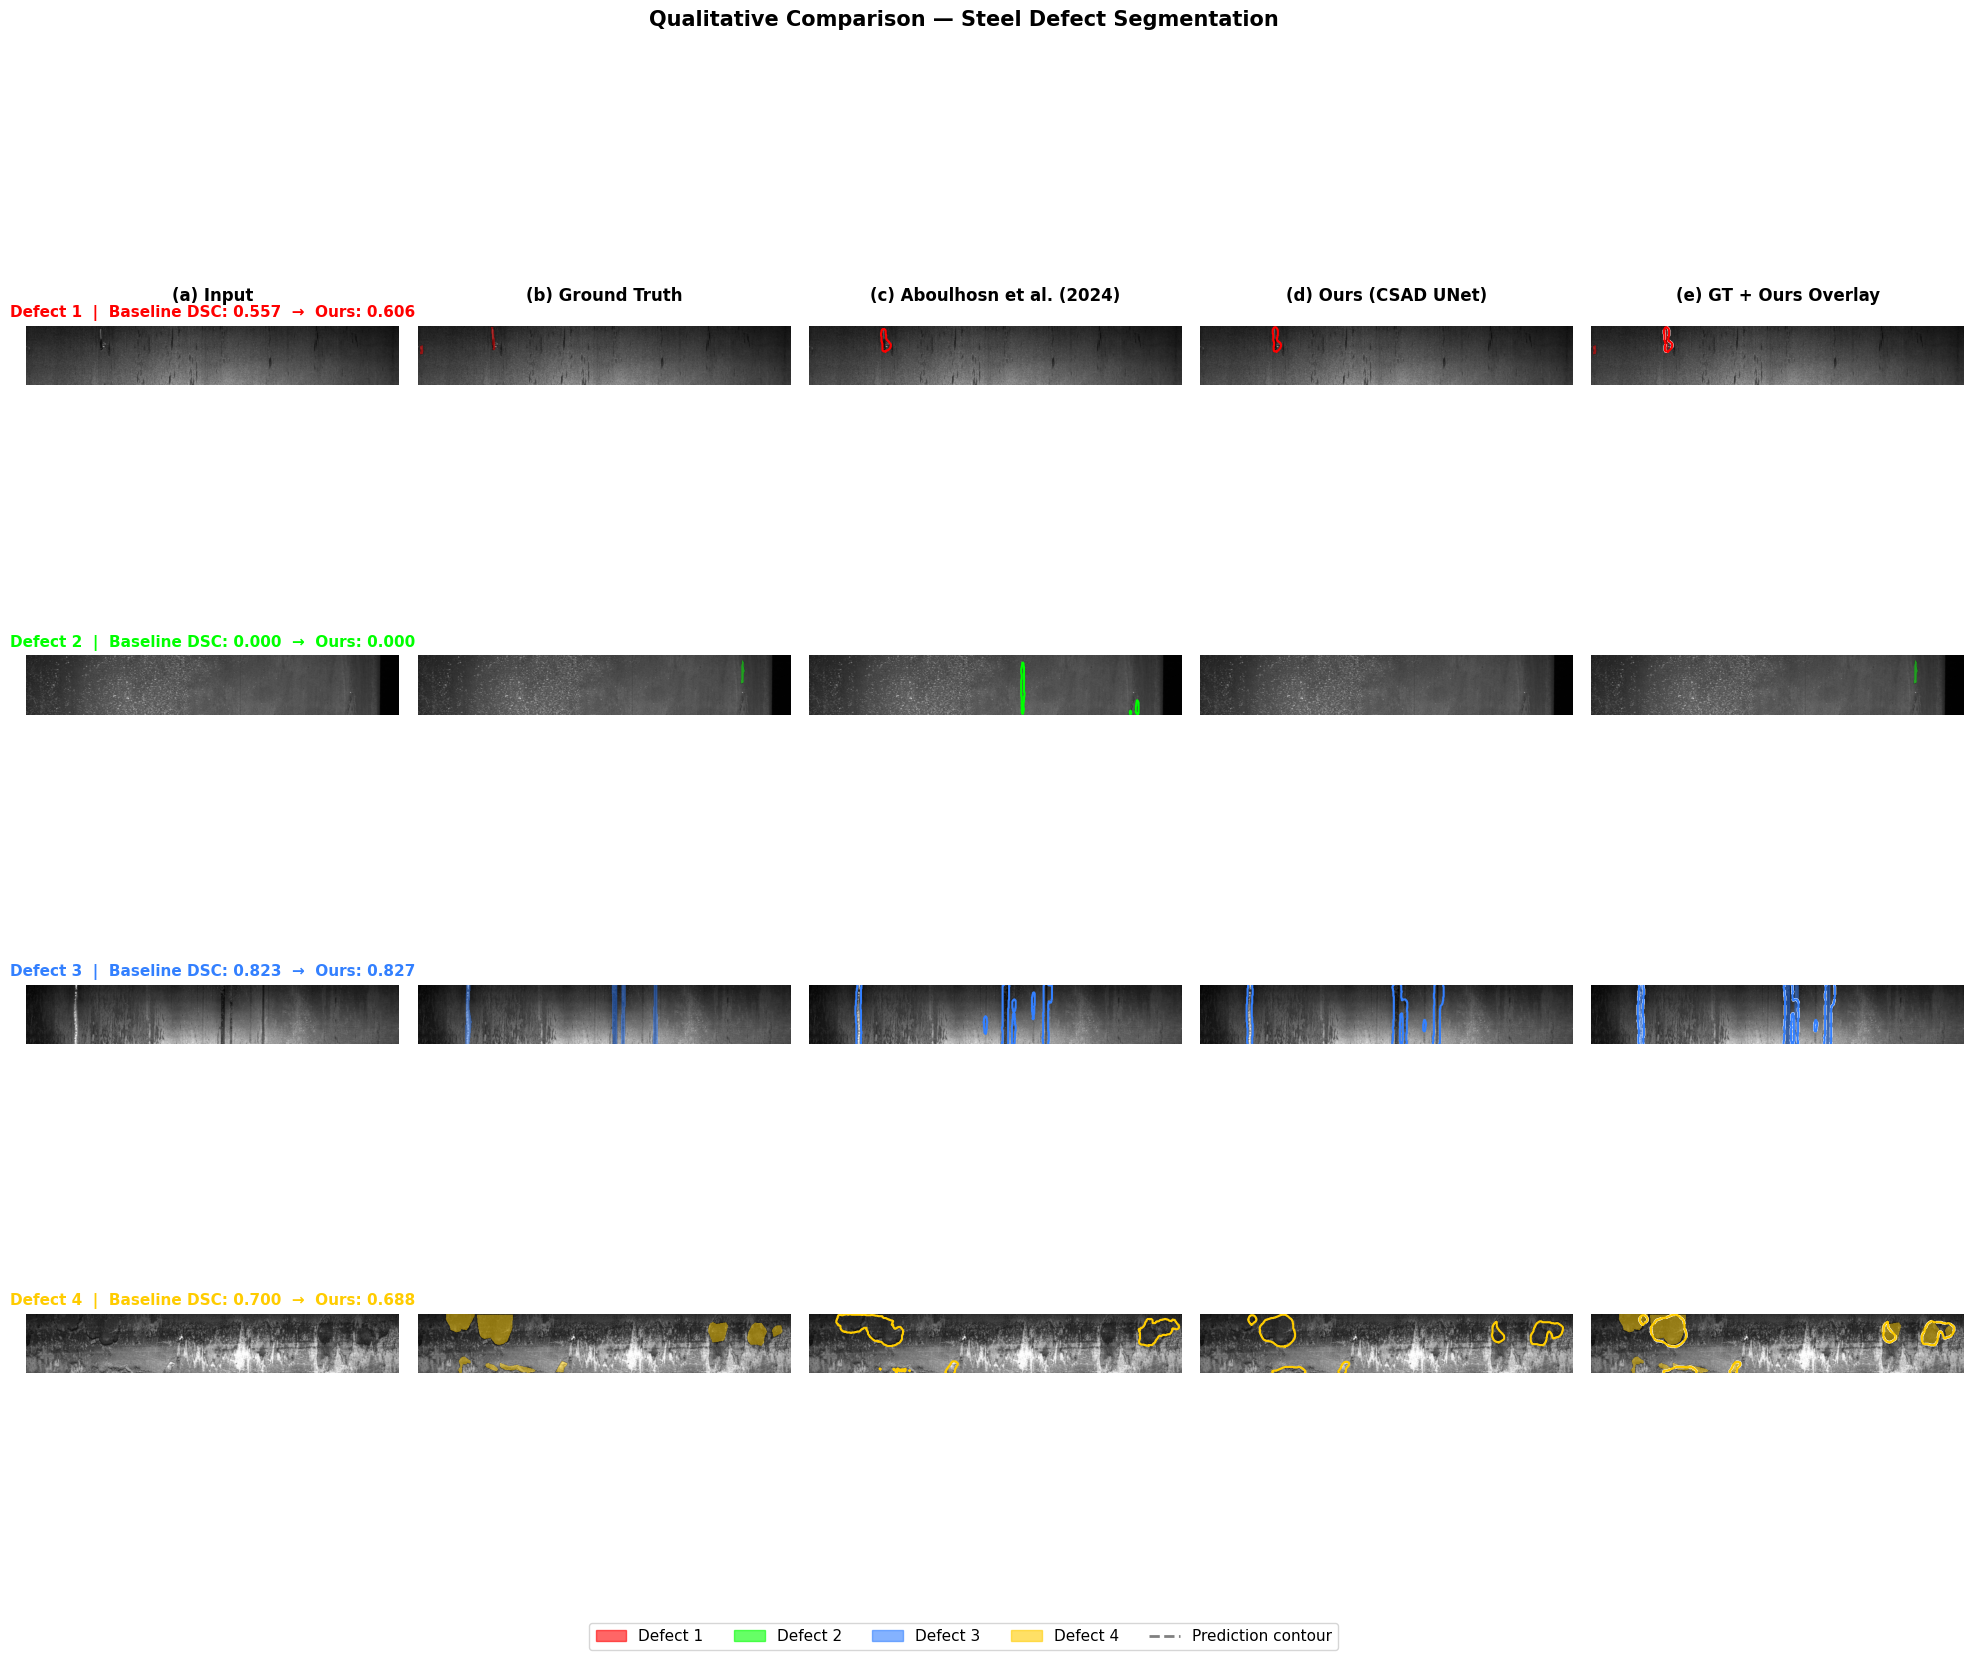

✅ 完成


In [ ]:
import random
from skimage import measure

def find_random_samples(groups, ids, target_classes=[0,1,2,3], seed=42):
    random.seed(seed)
    samples_per_class = {c: [] for c in target_classes}

    for img_id in ids:
        g = groups.get_group(img_id) if img_id in groups.groups else None
        if g is None:
            continue
        img_u8, mask_u8 = load_image_and_mask(img_id, g)
        for c in target_classes:
            if mask_u8[:, :, c].sum() > 0:
                samples_per_class[c].append((img_id, img_u8, mask_u8))

    result = {}
    for c in target_classes:
        if not samples_per_class[c]:
            result[c] = None
            print(f"  Defect {c+1}: 找不到樣本")
            continue
        img_id, img_u8, mask_u8 = random.choice(samples_per_class[c])
        img_f = preprocess_image(img_u8)
        result[c] = (img_id, img_u8, img_f, mask_u8)
        print(f"  Defect {c+1}: {img_id}")
    return result


def visualize_random_comparison(model_org, model, groups, ids,
                                thr=0.5, target_classes=[0,1,2,3], seed=42):
    print("隨機抽取樣本：")
    samples = find_random_samples(groups, ids,
                                  target_classes=target_classes, seed=seed)

    colors_rgb = [(1,0,0), (0,1,0), (0.2,0.5,1), (1,0.8,0)]
    class_names = ["Defect 1", "Defect 2", "Defect 3", "Defect 4"]
    n_rows = len(target_classes)
    col_titles = ["(a) Input", "(b) Ground Truth",
                  "(c) Aboulhosn et al. (2024)",
                  "(d) Ours (CSAD UNet)",
                  "(e) GT + Ours Overlay"]

    fig, axes = plt.subplots(n_rows, 5, figsize=(25, n_rows * 4),
                             gridspec_kw={'hspace': 0.35, 'wspace': 0.05})
    if n_rows == 1:
        axes = axes[np.newaxis, :]

    for row_idx, c in enumerate(target_classes):
        sample = samples[c]
        if sample is None:
            for col in range(5):
                axes[row_idx, col].axis('off')
            continue

        img_id, img_u8, img_f, mask_u8 = sample
        gt_bin_c = mask_u8[:, :, c] > 0

        pred_org = model_org.predict(img_f[np.newaxis], verbose=0)[0]
        pred_org_masks = [pred_org[:, :, i] >= thr for i in range(4)]
        preds = model.predict(img_f[np.newaxis], verbose=0)
        pred_masks = [p[0, :, :, 0] >= thr for p in preds]

        # 計算 DSC 顯示在標題
        eps = 1e-7
        def dsc(a, b):
            a, b = a.astype(np.uint8), b.astype(np.uint8)
            if a.sum() == 0 and b.sum() == 0: return 1.0
            return (2*(a&b).sum() + eps) / (a.sum() + b.sum() + eps)
        dsc_org  = dsc(gt_bin_c, pred_org_masks[c])
        dsc_ours = dsc(gt_bin_c, pred_masks[c])

        for col, (mode, pmask, pcolor) in enumerate([
            ('input',   None,              None),
            ('gt',      None,              None),
            ('base',    pred_org_masks[c], colors_rgb[c]),
            ('ours',    pred_masks[c],     colors_rgb[c]),
            ('overlay', pred_masks[c],     colors_rgb[c]),
        ]):
            ax = axes[row_idx, col]

            # 欄標題（只第一列）
            if row_idx == 0:
                ax.set_title(col_titles[col], fontsize=12,
                             fontweight='bold', pad=18, color='black')

            # 列標題（只第一欄）
            if col == 0:
                ax.text(0.5, 1.08,
                        f"{class_names[c]}  |  Baseline DSC: {dsc_org:.3f}  →  Ours: {dsc_ours:.3f}",
                        transform=ax.transAxes,
                        ha='center', va='bottom',
                        fontsize=11, fontweight='bold',
                        color=colors_rgb[c])

            # 底圖灰階
            ax.imshow(img_u8, cmap='gray')

            # GT 色塊（b、e 欄）
            if mode in ('gt', 'overlay'):
                color_layer = np.zeros((*img_u8.shape, 4), dtype=np.float32)
                color_layer[gt_bin_c] = [*colors_rgb[c], 0.5]
                ax.imshow(color_layer)

            # 預測輪廓
            if pmask is not None:
                contours = measure.find_contours(pmask.astype(float), 0.5)
                for contour in contours:
                    if mode == 'overlay':
                        ax.plot(contour[:, 1], contour[:, 0],
                                linewidth=2, color='white', linestyle='--')
                    ax.plot(contour[:, 1], contour[:, 0],
                            linewidth=1.5, color=pcolor)

            ax.axis('off')

    import matplotlib.patches as mpatches
    import matplotlib.lines as mlines
    patch_items = [mpatches.Patch(color=colors_rgb[c], alpha=0.6,
                   label=class_names[c]) for c in range(4)]
    line_item = mlines.Line2D([0], [0], color='gray', linewidth=2,
                              linestyle='--', label='Prediction contour')
    fig.legend(handles=patch_items + [line_item], loc='lower center',
               ncol=6, fontsize=11, bbox_to_anchor=(0.5, -0.01))

    plt.suptitle("Qualitative Comparison — Steel Defect Segmentation",
                 fontsize=15, fontweight='bold', y=1.02)
    plt.savefig("/content/drive/MyDrive/實驗結果/qualitative_random.png",
                dpi=200, bbox_inches='tight')
    plt.show()
    print("✅ 完成")


# 執行，換 seed 可以換一批圖
visualize_random_comparison(model_org, model, groups, te_ids, thr=0.5, seed=560)



Loaded: unet_efficientnetb4_none  backbone=efficientnetb4  multi_output=False
Loaded: unet_ag_shared_efficientnetb4  backbone=efficientnetb4  multi_output=True

Total models loaded: 2
UNet EfficientNetb4                 -> TARGET_LAYER: activation_9
UNet EfficientNetb4 AG (Indep. Decoder) -> TARGET_LAYER: {0: 'activation_44', 1: 'activation_55', 2: 'activation_66', 3: 'activation_77'}


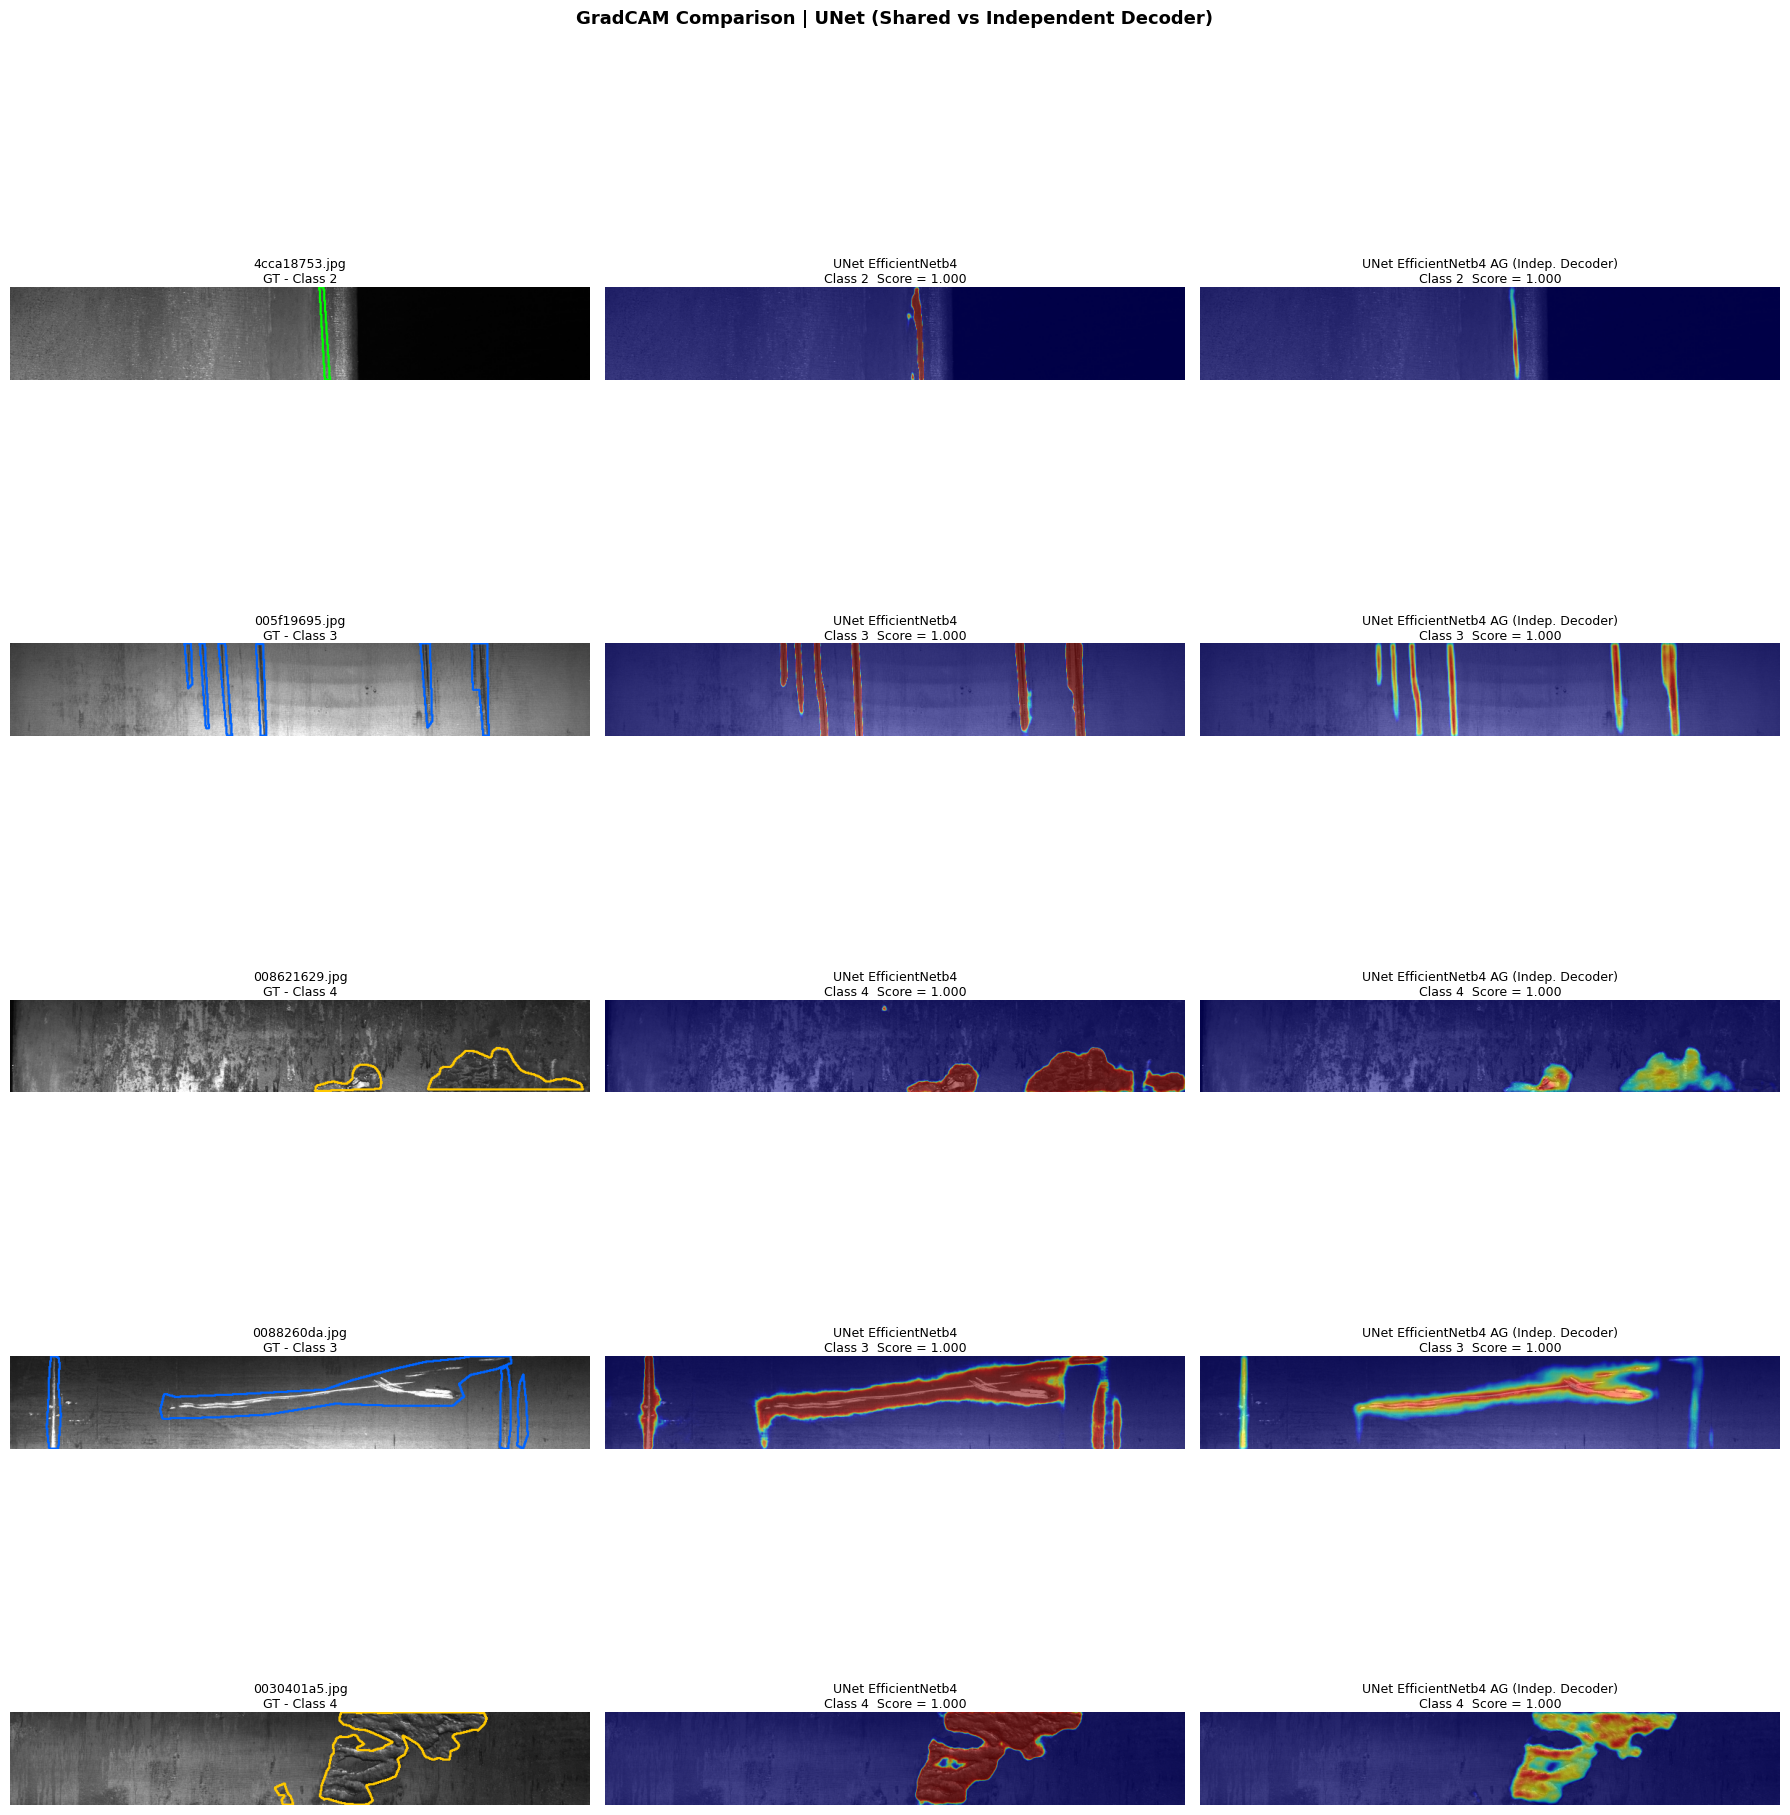

Done.


In [ ]:
# ============================================================
# GradCAM 多模型對比視覺化 — 支援獨立解碼器版本（最終完整版）
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import tensorflow as tf
import os

matplotlib.rcParams['font.family'] = 'DejaVu Sans'


# ── 1. 各模型前處理函式 ───────────────────────────────────────
def preprocess_for_model(img_u8, backbone):
    img = img_u8.astype("float32")
    if img.ndim == 2:
        img = np.stack([img] * 3, axis=-1)
    if img.shape[-1] == 1:
        img = np.repeat(img, 3, axis=-1)
    if backbone == "resnet50":
        return tf.keras.applications.resnet50.preprocess_input(img)
    elif backbone == "inceptionv3":
        return tf.keras.applications.inception_v3.preprocess_input(img)
    else:
        return tf.keras.applications.efficientnet.preprocess_input(img)


# ── 2. 載入模型（含 multi_output 標記）───────────────────────
models          = {}
backbone_map    = {}
is_multi_output = {}


NEW_MODEL_CONFIGS = {
    "UNet EfficientNetb4":    ("unet_efficientnetb4_none",    "efficientnetb4", False),

    "UNet EfficientNetb4 AG (Indep. Decoder)":
        ("unet_ag_shared_efficientnetb4", "efficientnetb4", True),
}


for display_name, (fname, backbone, multi_out) in NEW_MODEL_CONFIGS.items():
    path = f"{MODEL_DIR}/{fname}.keras"
    if os.path.exists(path):
        models[display_name]          = tf.keras.models.load_model(
            path, custom_objects=CUSTOM_OBJECTS, safe_mode=False)
        backbone_map[display_name]    = backbone
        is_multi_output[display_name] = multi_out
        print(f"Loaded: {fname}  backbone={backbone}  multi_output={multi_out}")
    else:
        print(f"Not found: {path}")

print(f"\nTotal models loaded: {len(models)}")


# ── 3. TARGET_LAYER 設定 ──────────────────────────────────────
target_layers = {
    "UNet EfficientNetb4":    "activation_9",
    "UNet EfficientNetb4 AG (Indep. Decoder)": {
        0: "activation_44",
        1: "activation_55",
        2: "activation_66",
        3: "activation_77",
    },
}

for display_name, layer in target_layers.items():
    print(f"{display_name:35s} -> TARGET_LAYER: {layer}")


# ── 4. GradCAM 函式（支援動態層名 + multi_output）──────────────
def gradcam_seg(model, img_u8, class_idx, layer_name_or_dict, backbone, multi_output=False):
    """
    img_u8             : shape (H, W, 3)，值域 [0, 255]
    layer_name_or_dict :
        - 字串：固定層名（共用輸出模型）
        - dict：依 class_idx 查表（獨立解碼器模型）
    backbone     : 用於正確前處理
    multi_output : True 表示模型輸出是 list of 4 個 (B,H,W,1)
    """
    if isinstance(layer_name_or_dict, dict):
        layer_name = layer_name_or_dict[class_idx]
    else:
        layer_name = layer_name_or_dict

    img_processed = preprocess_for_model(img_u8, backbone)
    img_tensor    = tf.cast(img_processed[np.newaxis], tf.float32)

    try:
        grad_model = tf.keras.Model(
            inputs=model.input,
            outputs=[model.get_layer(layer_name).output, model.output]
        )
    except Exception as e:
        print(f"Layer error '{layer_name}': {e}")
        return None, None

    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_tensor, training=False)

        if multi_output:
            pred_c = preds[class_idx][0, ..., 0]
        else:
            pred_c = preds[0, ..., int(class_idx)]

        threshold = tf.reduce_max(pred_c) * 0.5
        mask      = tf.cast(pred_c > threshold, tf.float32)
        denom     = tf.reduce_sum(mask) + 1e-8
        score     = tf.reduce_sum(pred_c * mask) / denom

    grads = tape.gradient(score, conv_out)
    if grads is None:
        return None, None

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam     = tf.reduce_sum(weights * conv_out[0], axis=-1)
    cam     = tf.maximum(cam, 0).numpy()

    if cam.max() < 1e-8:
        return None, None

    cam = cam / cam.max()
    cam = cv2.resize(cam, (INPUT_W, INPUT_H))

    if multi_output:
        score_val = float(preds[class_idx].numpy()[0, ..., 0].max())
    else:
        score_val = float(preds.numpy()[0, ..., int(class_idx)].max())

    return cam, score_val


# ── 5. 目標圖片與類別 ─────────────────────────────────────────
targets = {
    '4cca18753.jpg':  [2],
    '005f19695.jpg':  [3],
    '008621629.jpg':  [4],
    '0088260da.jpg':  [3],
    '0030401a5.jpg':  [4],
}

COLORS = {1: (255, 0, 0), 2: (0, 255, 0), 3: (255, 100, 0), 4: (0, 200, 255)}

df_gt = pd.read_csv(TRAIN_CSV)
if "ImageId_ClassId" in df_gt.columns:
    df_gt["ImageId"] = df_gt["ImageId_ClassId"].apply(lambda x: x.split("_")[0])
    df_gt["ClassId"] = df_gt["ImageId_ClassId"].apply(lambda x: int(x.split("_")[1]))
df_gt = df_gt.set_index(["ImageId", "ClassId"])


# ── 6. 視覺化 ─────────────────────────────────────────────────
total_rows = sum(len(cids) for cids in targets.values())
n_cols     = 1 + len(models)

fig, axes = plt.subplots(
    total_rows, n_cols,
    figsize=(6 * n_cols, 4.0 * total_rows)
)
if total_rows == 1:
    axes = axes[np.newaxis, :]

row = 0
for fname, class_ids in targets.items():
    path = os.path.join(TRAIN_DIR, fname)
    if not os.path.exists(path):
        print(f"Image not found: {path}")
        row += len(class_ids)
        continue

    img_raw   = cv2.imread(path)
    img_small = cv2.resize(img_raw, (INPUT_W, INPUT_H))
    img_rgb   = cv2.cvtColor(img_small, cv2.COLOR_BGR2RGB)

    for cid in class_ids:
        class_idx = cid - 1

        # ── Col 0：原圖 + GT ──────────────────────────────────
        img_gt = img_small.copy()
        if (fname, cid) in df_gt.index:
            rle = df_gt.loc[(fname, cid), "EncodedPixels"]
            if isinstance(rle, pd.Series):
                rle = rle.iloc[0]
            mask   = rle_decode(rle, (256, 1600))
            mask_s = cv2.resize(mask, (INPUT_W, INPUT_H))
            cnts, _ = cv2.findContours(
                mask_s, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(img_gt, cnts, -1, COLORS[cid], 2)

        axes[row, 0].imshow(cv2.cvtColor(img_gt, cv2.COLOR_BGR2RGB))
        axes[row, 0].set_title(f"{fname}\nGT - Class {cid}", fontsize=9, pad=3)
        axes[row, 0].axis("off")

        # ── Col 1~N：各模型 GradCAM ───────────────────────────
        for col_idx, (display_name, m) in enumerate(models.items(), start=1):
            backbone   = backbone_map[display_name]
            layer_name = target_layers[display_name]
            multi_out  = is_multi_output[display_name]

            cam, score_val = gradcam_seg(
                m, img_small, class_idx, layer_name, backbone,
                multi_output=multi_out)

            if cam is not None:
                heatmap     = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
                heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
                overlay     = cv2.addWeighted(img_rgb, 0.45, heatmap_rgb, 0.55, 0)
                axes[row, col_idx].imshow(overlay)
                axes[row, col_idx].set_title(
                    f"{display_name}\nClass {cid}  Score = {score_val:.3f}",
                    fontsize=9, pad=3)
            else:
                axes[row, col_idx].imshow(np.zeros_like(img_rgb))
                axes[row, col_idx].set_title(
                    f"{display_name}\nCannot generate",
                    fontsize=9, pad=3)

            axes[row, col_idx].axis("off")

        row += 1

plt.suptitle(
    "GradCAM Comparison | UNet (Shared vs Independent Decoder)",
    fontsize=13, y=1.01, fontweight="bold"
)
plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/實驗結果/gradcam_comparison_unet_with_indep_decoder.png",
    dpi=150, bbox_inches="tight"
)
plt.show()
print("Done.")